# Predikcia Pulzaru (rýchlo rotujúcej neutrónovej hviezdy)
Vypracovala: Simona Bednáriková
Dátum: 24.11.2026

## Kontext
Pulsary sú vzácnym typom neutrónových hviezd, ktoré vyžarujú rádiové vlny, ktoré dokážeme zachytiť aj tu na Zemi. Vznikajú po výbuchu supernovy.

Sú pre vedeckú komunitu nástrojom na skúmanie vesmíru. Potrebujeme ich vedieť identifikovať napr. na:
- pochopenie extrémnej hmoty: Na Zemi nedokážeme stlačiť hmotu tak silno ako v pulzare. Sledovaním pulzarov zisťujeme, ako sa v takých extrémoch správajú atómy a magnetizmus.
- meranie vesmíru či gravitačných vĺn: tzv. milisekundové pulzary blikajú rovnako presne ako atómové hodinky, stačí sledovať, či ich signál k nám mešká alebo ide skôr. Z toho vieme zistiť, či cez vesmír prešla gravitačná vlna alebo či je medzi nami a pulzarom nejaký neviditeľný objekt (napr. čierna diera).

##Ako ich vieme na oblohe identifikovať? High Time Resolution Universe (HTRU)
Toto meranie zachytáva rýchle rádiové záblesky a pravidelné pulzy z vesmíru (milisekundové pulzary a jednorazové záblesky zvané Fast Radio Bursts).

Vykonáva sa pomocou systematického skenovanie celej oblohy pomocou rádioteleskopov. Parkes v Austrálii (južná obloha) a Effelsberg v Nemecku (severná obloha). Tieto teleskopy zachytávajú:
- rádiové vlny (nie svetlo): zachytávajú rádiový šum z vesmíru na frekvencii okolo 1,4 GHz (podobné pásmo, aké používajú napr. satelity alebo Wi-Fi).
- extrémne krátke zmeny: Prístroje merajú silu rádiového signálu každých 54 až 64 mikrosekúnd (cca 15 000/s). Vďaka tomu zachytia aj záblesk, ktorý trvá len zlomok milisekundy.
- Rozdelenie na stovky „farieb“: Zachytávaný rádiový signál nie je jeden celok – digitálny prijímač ho rozseká na stovky úzkych frekvenčných kanálov

##Cieľ projektu - binárna klasifikácia
Rádioteleskopy pri hľadaní pulzarov zachytia obrovské množstvo kandidátov, no takmer všetky sú len rušenie (mobilné siete, satelity, šum prístrojov). Skutočných pulzarov je málo. Naším cieľom binárna klasifikácia a teda naučiť model  **rozhodnúť, či je kandidát skutočný pulzar (1) alebo šum (0)**.

## Dáta
Dáta sú verejné sťahujeme ich priamo z Kaggle: https://www.kaggle.com/datasets/charitarth/pulsar-dataset-htru2

Jedná sa o kandidátov na pulsary. Dáta boli zhromaždené v rámci prieskumu High Time Resolution Universe (HTRU).

### Informácie o atribútoch
Každý kandidát je opísaný **8 spojitými premennými** a jednou **cieľovou premennou** (0/1).
Prvé štyri premenné sú štatistiky integrovaného pulzného profilu, ďalšie štyri sú tie isté štatistiky DM-SNR krivky.

Integrovaný pulzný profil - každý pulzar vysiela pulzy v typickom vzore, tzv. pulznom profile. Je to akoby jeho odtlačok prsta, podľa ktorého sa dá pulzar rozpoznať. Profil sa však pri každej otáčke trochu líši, signál nie je rovnomerný ani stabilný v čase, a preto je ťažké pulzar zachytiť. Stabilný tvar získame až vtedy, keď profil spriemerujeme cez tisíce otáčok. Skutočný pulzar má úzky a ostrý pulz, šum je plochý.

DM-SNR krivka. Rádiové vlny z pulzaru putujú na Zem cez vesmír, ktorý je plný voľných elektrónov. Pri interakcii s nimi sa vlny spomaľujú, a to tým viac, čím majú nižšiu frekvenciu. Pulzar vysiela na širokom rozsahu frekvencií, takže nižšie frekvencie dorazia k teleskopu neskôr ako vyššie. Tento jav sa nazýva disperzia a jej mieru udáva DM (*dispersion measure*). DM-SNR krivka ukazuje, aký silný je signál (SNR, pomer signálu a šumu) pri rôznych hodnotách DM. Signál zo skutočného pulzaru je najsilnejší pri DM > 0, kým pozemské rušenie, ktoré cez vesmír necestovalo, je najsilnejšie pri DM ≈ 0.

*Opisy kriviek voľne podľa [Utsav Murarka: Pulsar-identification](https://github.com/UtsavMurarka/Pulsar-identification).*

| # | Premenná v datasete | Opis | Rozsah (min – max) | Bežné hodnoty (5. – 95. percentil) | Medián šum / pulzar |
|---|---|---|---|---|---|
| 1 | `mean_profile` | stredná hodnota integrovaného profilu | 5,8 – 192,6 | 57 – 143 | 117,3 / 54,3 |
| 2 | `std_profile` | smerodajná odchýlka integrovaného profilu | 24,8 – 98,8 | 35 – 56 | 47,5 / 37,3 |
| 3 | `kurtosis_profile` | nadmerná špicatosť integrovaného profilu, teda aký ostrý je pulz | −1,9 – 8,1 | −0,2 – 2,7 | 0,2 / 3,0 |
| 4 | `skewness_profile` | šikmosť integrovaného profilu, teda nakoľko je pulz nesymetrický | −1,8 – 68,1 | −0,6 – 10,1 | 0,1 / 11,6 |
| 5 | `mean_dmsnr` | stredná hodnota DM-SNR krivky | 0,2 – 223,4 | 1,0 – 83,0 | 2,6 / 33,5 |
| 6 | `std_dmsnr` | smerodajná odchýlka DM-SNR krivky | 7,4 – 110,6 | 11 – 75 | 17,6 / 59,4 |
| 7 | `kurtosis_dmsnr` | nadmerná špicatosť DM-SNR krivky | −3,1 – 34,5 | 0,5 – 15,8 | 8,8 / 1,9 |
| 8 | `skewness_dmsnr` | šikmosť DM-SNR krivky | −2,0 – 1 191,0 | −0,5 – 296,4 | 90,7 / 2,6 |
| 9 | `target_pulsar` | **cieľová premenná**: 1 = pulzar, 0 = šum | 0 / 1 | – | – |

### Súhrn datasetu
| | Počet | Podiel |
|---|---|---|
| Všetky pozorovania | 17 898 | 100 % |
| Pulzary (1) | 1 639 | 9,2 % |
| Šum (0) | 16 259 | 90,8 % |

Premenné majú **veľmi rozdielne mierky** (napr. `kurtosis_profile` do 8, `skewness_dmsnr` až do 1 191). Preto ich pred modelmi založenými na vzdialenostiach budeme škálovať.

## Postup (podľa zadania)
1. Exploratívna analýza a príprava dát
2. Výber algoritmov a zdôvodnenie
3. Rozdelenie na trénovaciu a testovaciu časť
4. Trénovanie, optimalizácia hyperparametrov, vyhodnotenie a porovnanie modelov
---
Čo je pulsar: https://youtu.be/gjLk_72V9Bw?si=Co4abs6ldhKkJtZQ


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (train_test_split, cross_val_score,GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score,
                             classification_report,
                             ConfusionMatrixDisplay,
                             RocCurveDisplay)
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter
import os


# 1. Exploratívna analýza dát
## 1.1 Načítanie dát z Kaggle

In [18]:
path = kagglehub.dataset_download("charitarth/pulsar-dataset-htru2")
print(os.listdir(path))

columns = ["mean_profile", "std_profile", "kurtosis_profile",
           "skewness_profile", "mean_dmsnr", "std_dmsnr",
           "kurtosis_dmsnr", "skewness_dmsnr", "target_pulsar"]

df = pd.read_csv(f"{path}/HTRU_2.csv", header=None, names=columns)

print("#riadkov, #stĺpcov:",df.shape)
print("Názvy stĺpcov:", df.columns)
df.head()


Using Colab cache for faster access to the 'pulsar-dataset-htru2' dataset.
['HTRU_2.csv']
#riadkov, #stĺpcov: (17898, 9)
Názvy stĺpcov: Index(['mean_profile', 'std_profile', 'kurtosis_profile', 'skewness_profile',
       'mean_dmsnr', 'std_dmsnr', 'kurtosis_dmsnr', 'skewness_dmsnr',
       'target_pulsar'],
      dtype='object')


,mean_profile,std_profile,kurtosis_profile,skewness_profile,mean_dmsnr,std_dmsnr,kurtosis_dmsnr,skewness_dmsnr,target_pulsar
0,140.562500,55.683782,-0.234571,-0.699648,3.199833,19.110426,7.975532,74.242225,0
1,102.507812,58.882430,0.465318,-0.515088,1.677258,14.860146,10.576487,127.393580,0
2,103.015625,39.341649,0.323328,1.051164,3.121237,21.744669,7.735822,63.171909,0
3,136.750000,57.178449,-0.068415,-0.636238,3.642977,20.959280,6.896499,53.593661,0
4,88.726562,40.672225,0.600866,1.123492,1.178930,11.468720,14.269573,252.567306,0


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17898 entries, 0 to 17897
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   mean_profile      17898 non-null  float64
 1   std_profile       17898 non-null  float64
 2   kurtosis_profile  17898 non-null  float64
 3   skewness_profile  17898 non-null  float64
 4   mean_dmsnr        17898 non-null  float64
 5   std_dmsnr         17898 non-null  float64
 6   kurtosis_dmsnr    17898 non-null  float64
 7   skewness_dmsnr    17898 non-null  float64
 8   target_pulsar     17898 non-null  int64  
dtypes: float64(8), int64(1)
memory usage: 1.2 MB


Dataset má 17 898 pozorovaní, indexy od 0 po 17 897, 9 stĺpcov, z toho 8 vysvetľujúcich a 1 cieľová premenná.

Nemáme žiadne chýbajúce hodnoty (17898 = #riadkov).
Nie je teda potrebné nič doplniť ani mazať či nahrádzať.

Všetkých 8 vysvetľujúcich premenných je dátového typu float64, čiže spojité desatinné čísla,

target_pulsar má dátový typ int64, je to naša cieľová premenná  - celé číslo 0/1.
Žiadny stĺpec nie je textový (object), takže netreba kódovanie kategórií (one-hot a pod.).
Dataset má 1,2 MB - je teda malý a modely by sa mali dať natrénovať veľmi rýchlo.


In [ ]:
print("Chýbajúce hodnoty:", df.isna().sum().sum())
print("Duplicitné riadky:", df.duplicated().sum())

Chýbajúce hodnoty: 0
Duplicitné riadky: 0


Dáta **neobsahujú chýbajúce hodnoty ani duplicity**, takže imputáciu ani odstraňovanie riadkov netreba.

## 1.2 Opisné štatistiky

In [ ]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
mean_profile,17898.0,111.08,25.65,5.81,100.93,115.08,127.09,192.62
std_profile,17898.0,46.55,6.84,24.77,42.38,46.95,51.02,98.78
kurtosis_profile,17898.0,0.48,1.06,-1.88,0.03,0.22,0.47,8.07
skewness_profile,17898.0,1.77,6.17,-1.79,-0.19,0.20,0.93,68.10
mean_dmsnr,17898.0,12.61,29.47,0.21,1.92,2.80,5.46,223.39
std_dmsnr,17898.0,26.33,19.47,7.37,14.44,18.46,28.43,110.64
kurtosis_dmsnr,17898.0,8.30,4.51,-3.14,5.78,8.43,10.70,34.54
skewness_dmsnr,17898.0,104.86,106.51,-1.98,34.96,83.06,139.31,1191.00
target_pulsar,17898.0,0.09,0.29,0.00,0.00,0.00,0.00,1.00


* Premenné majú **veľmi rozdielne mierky**: `kurtosis_profile` sa pohybuje približne od −2 do 8, `skewness_dmsnr` až do 1 191. Pre modely založené na vzdialenostiach bude preto nutné škálovanie.
* Pri viacerých premenných je **maximum ďaleko od 75. percentilu** (napr. `mean_dmsnr`: Q3 = 5,5, max = 223). Ide o silne zošikmené rozdelenia s odľahlými hodnotami, ktoré preskúmame nižšie.
* Priemer `target_pulsar` je 0,09, teda **iba 9 % kandidátov sú pulzary**.

## 1.3 Závislá premenná: koľko je pulzarov?

target_pulsar
0    16259
1     1639
Name: count, dtype: int64


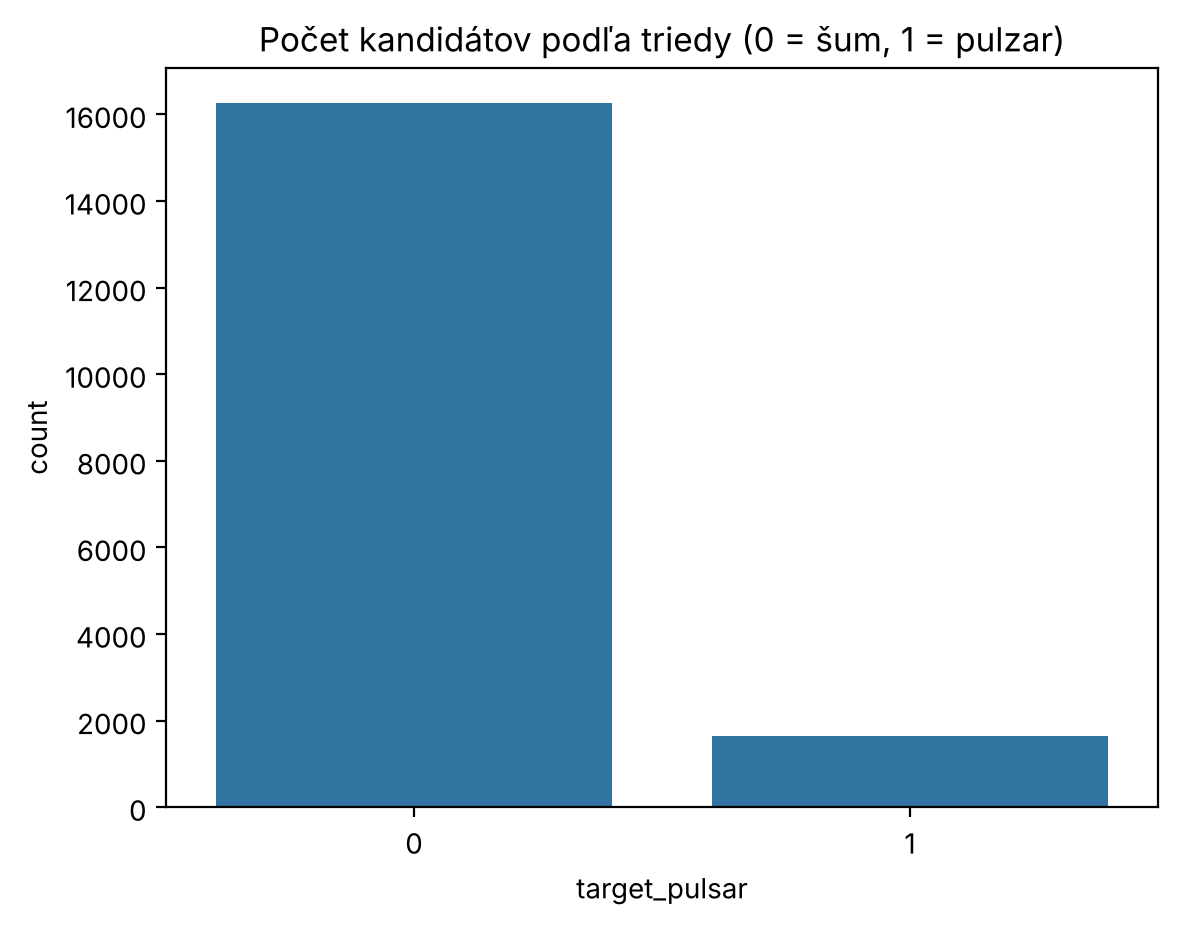

In [ ]:
print(df["target_pulsar"].value_counts())
sns.countplot(data=df, x="target_pulsar")
plt.title("Počet kandidátov podľa triedy (0 = šum, 1 = pulzar)")
plt.show()

**Triedy sú výrazne nevyvážené**: 16 259 kandidátov je šum a len 1 639 (9,2 %) sú pulzary. Z toho vyplývajú tri rozhodnutia:
1. dáta budeme deliť **stratifikovane** (rovnaký podiel pulzarov v train aj test),
2. modely nebudeme hodnotiť iba cez accuracy, ale hlavne cez **recall, precision a F1**,
3. vyskúšame parameter **`class_weight="balanced"`**, ktorý dáva väčšiu váhu chybám na menšinovej triede.

## 1.4 Rozdelenie premenných podľa triedy
Pre každú premennú porovnáme, ako vyzerá jej rozdelenie pri šume a pri pulzaroch.
Čím menej sa krivky prekrývajú, tým lepšie premenná triedy oddeľuje.

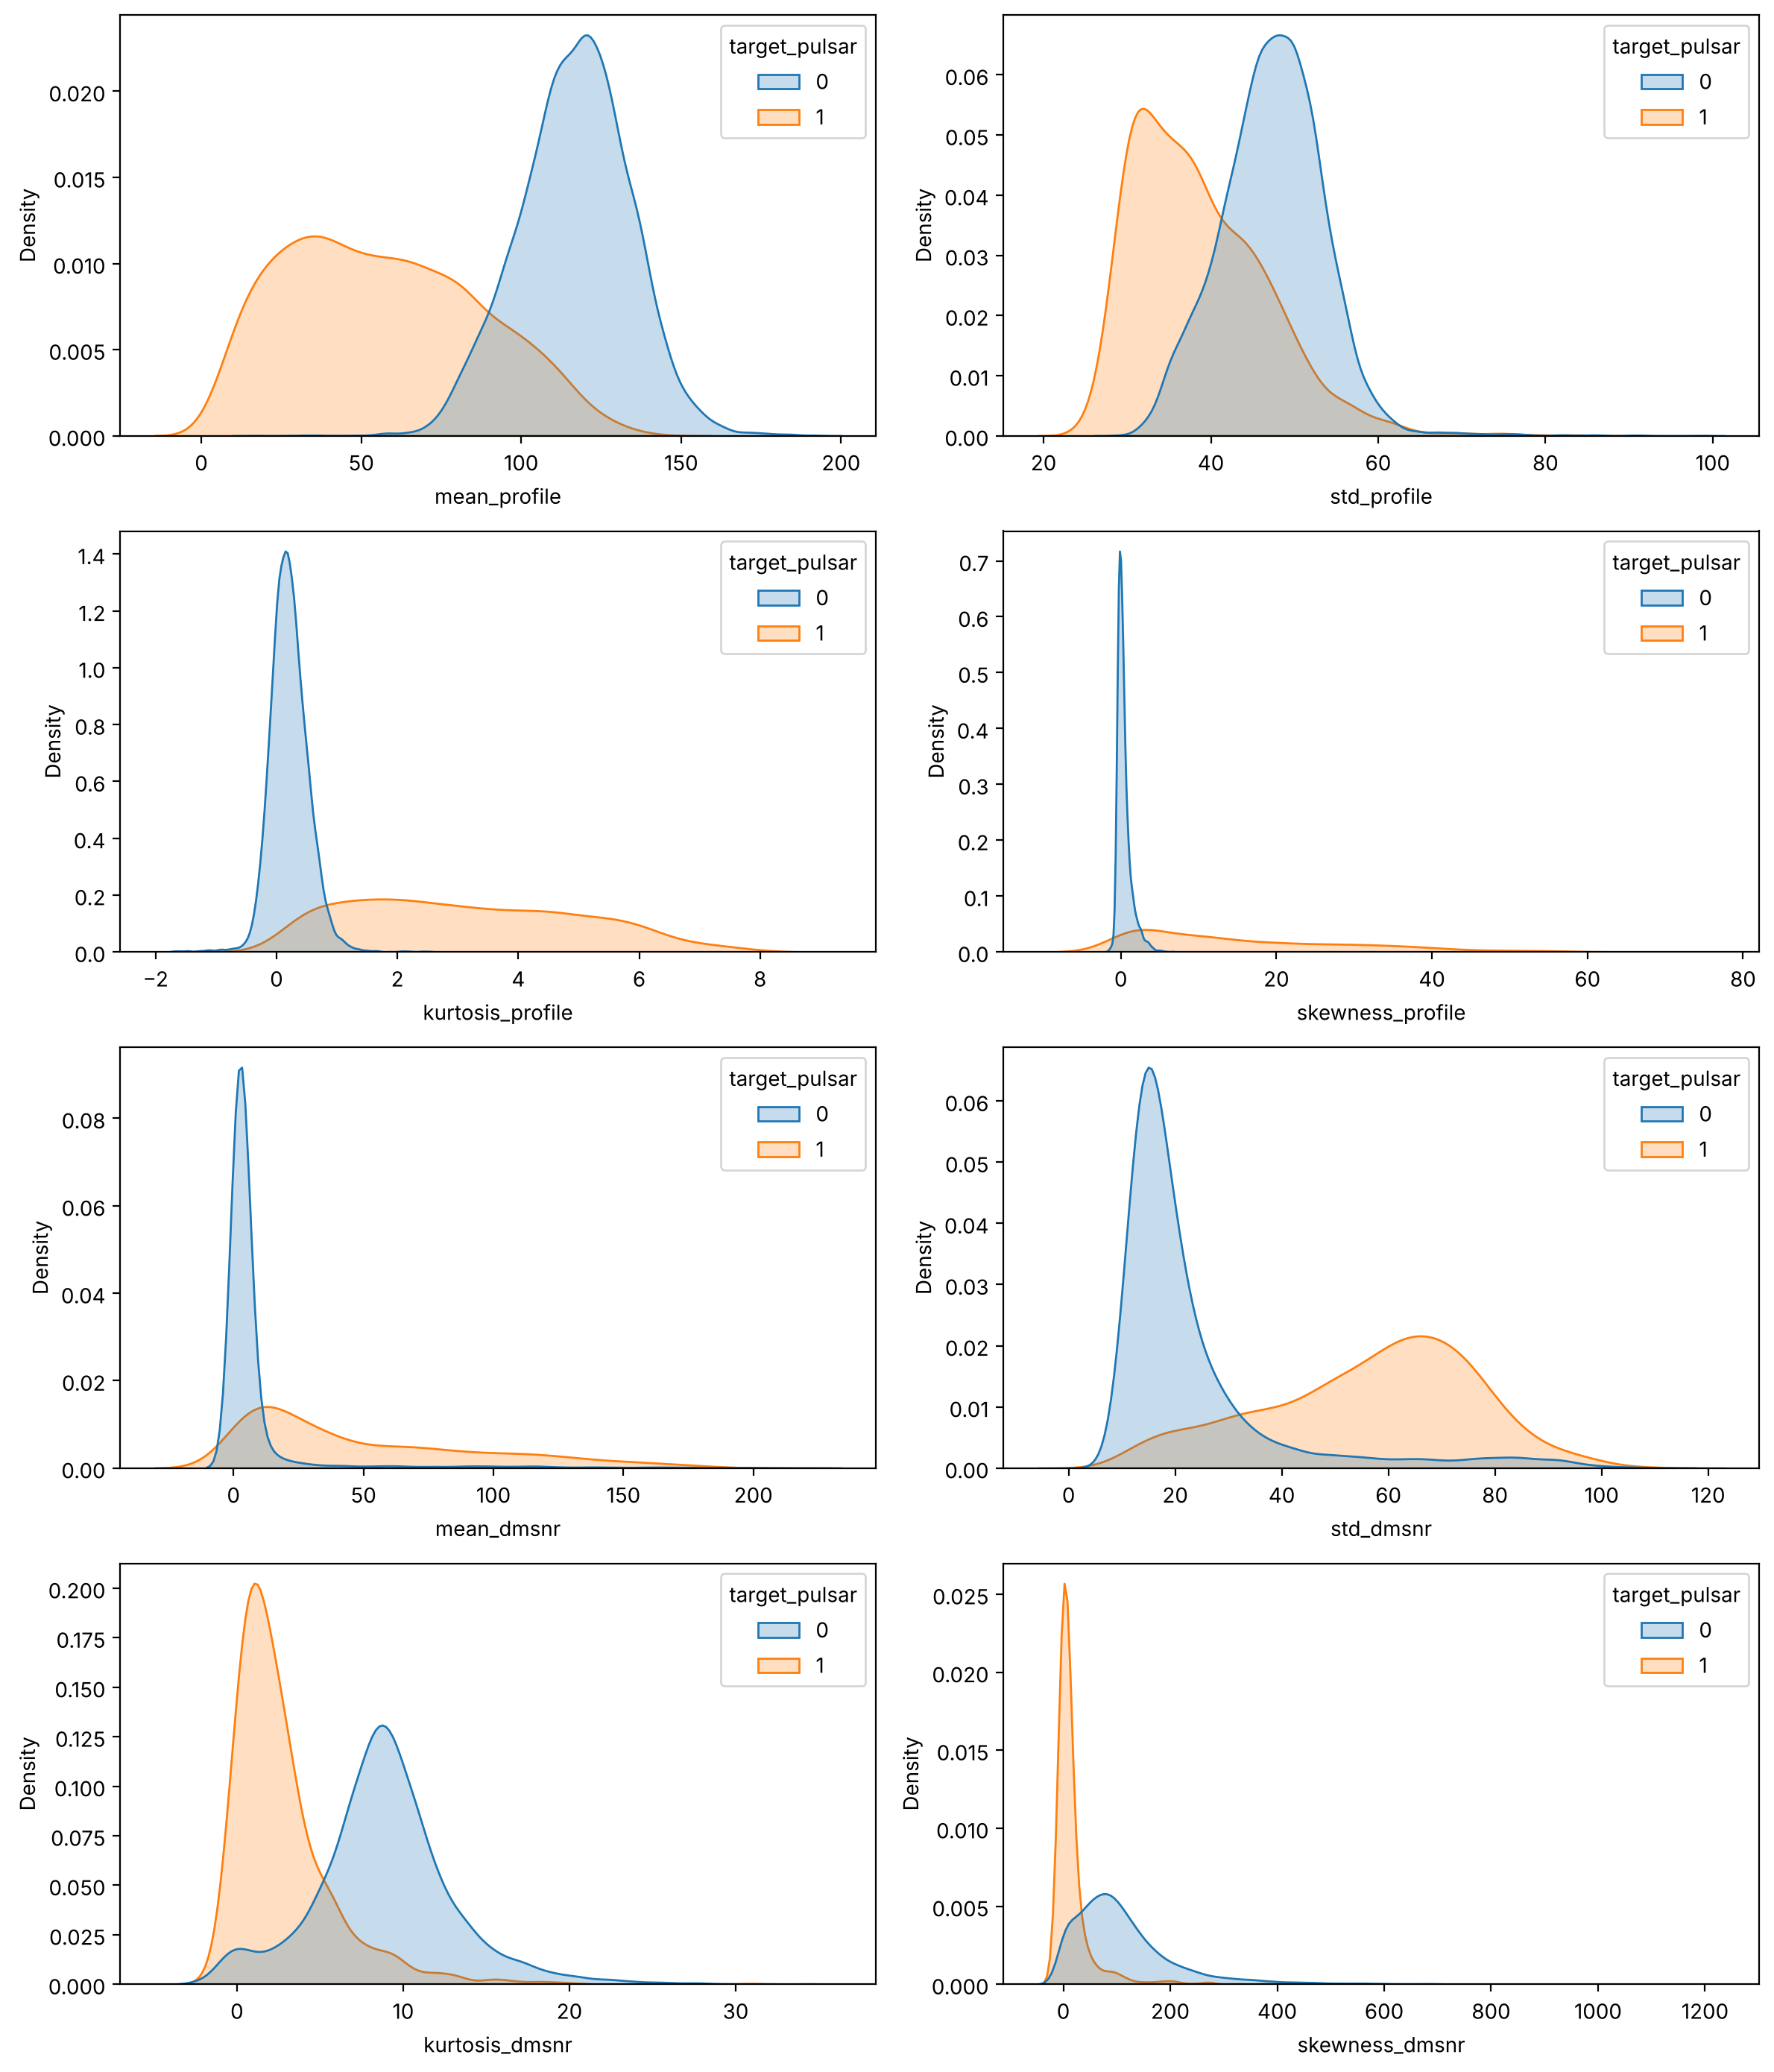

In [ ]:
features = df.columns.drop("target_pulsar")

fig, axes = plt.subplots(4, 2, figsize=(12, 14))
for ax, col in zip(axes.flat, features):
    sns.kdeplot(data=df, x=col, hue="target_pulsar",
                common_norm=False, fill=True, ax=ax)
plt.tight_layout()
plt.show()

* **Najlepšie oddeľujú triedy premenné integrovaného profilu.** Šum má `kurtosis_profile` sústredenú okolo 0, kým pulzary majú hodnoty 1 až 8. Pulzar má totiž úzky, ostrý pulz (špicaté rozdelenie), kým šum je plochý. Podobne pulzary majú výrazne nižší `mean_profile`.
* Pri **DM-SNR krivke** majú pulzary vyšší `mean_dmsnr` a `std_dmsnr`. Skutočný pulzar má silný signál pri konkrétnej hodnote rozptylu (DM > 0), kým pozemské rušenie je najsilnejšie pri DM ≈ 0.
* `skewness_profile` vyzerá takmer ako `kurtosis_profile` a `skewness_dmsnr` ako `kurtosis_dmsnr`. To overíme v korelačnej matici.

## 1.5 Odľahlé pozorovania
Odľahlé hodnoty hľadáme metódou **IQR**: hodnota je odľahlá, ak leží mimo intervalu
**[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]**, kde IQR = Q3 − Q1 (Q1, Q3 sú 25. a 75. percentil).
Zároveň zistíme, koľko percent odľahlých hodnôt patrí pulzarom.

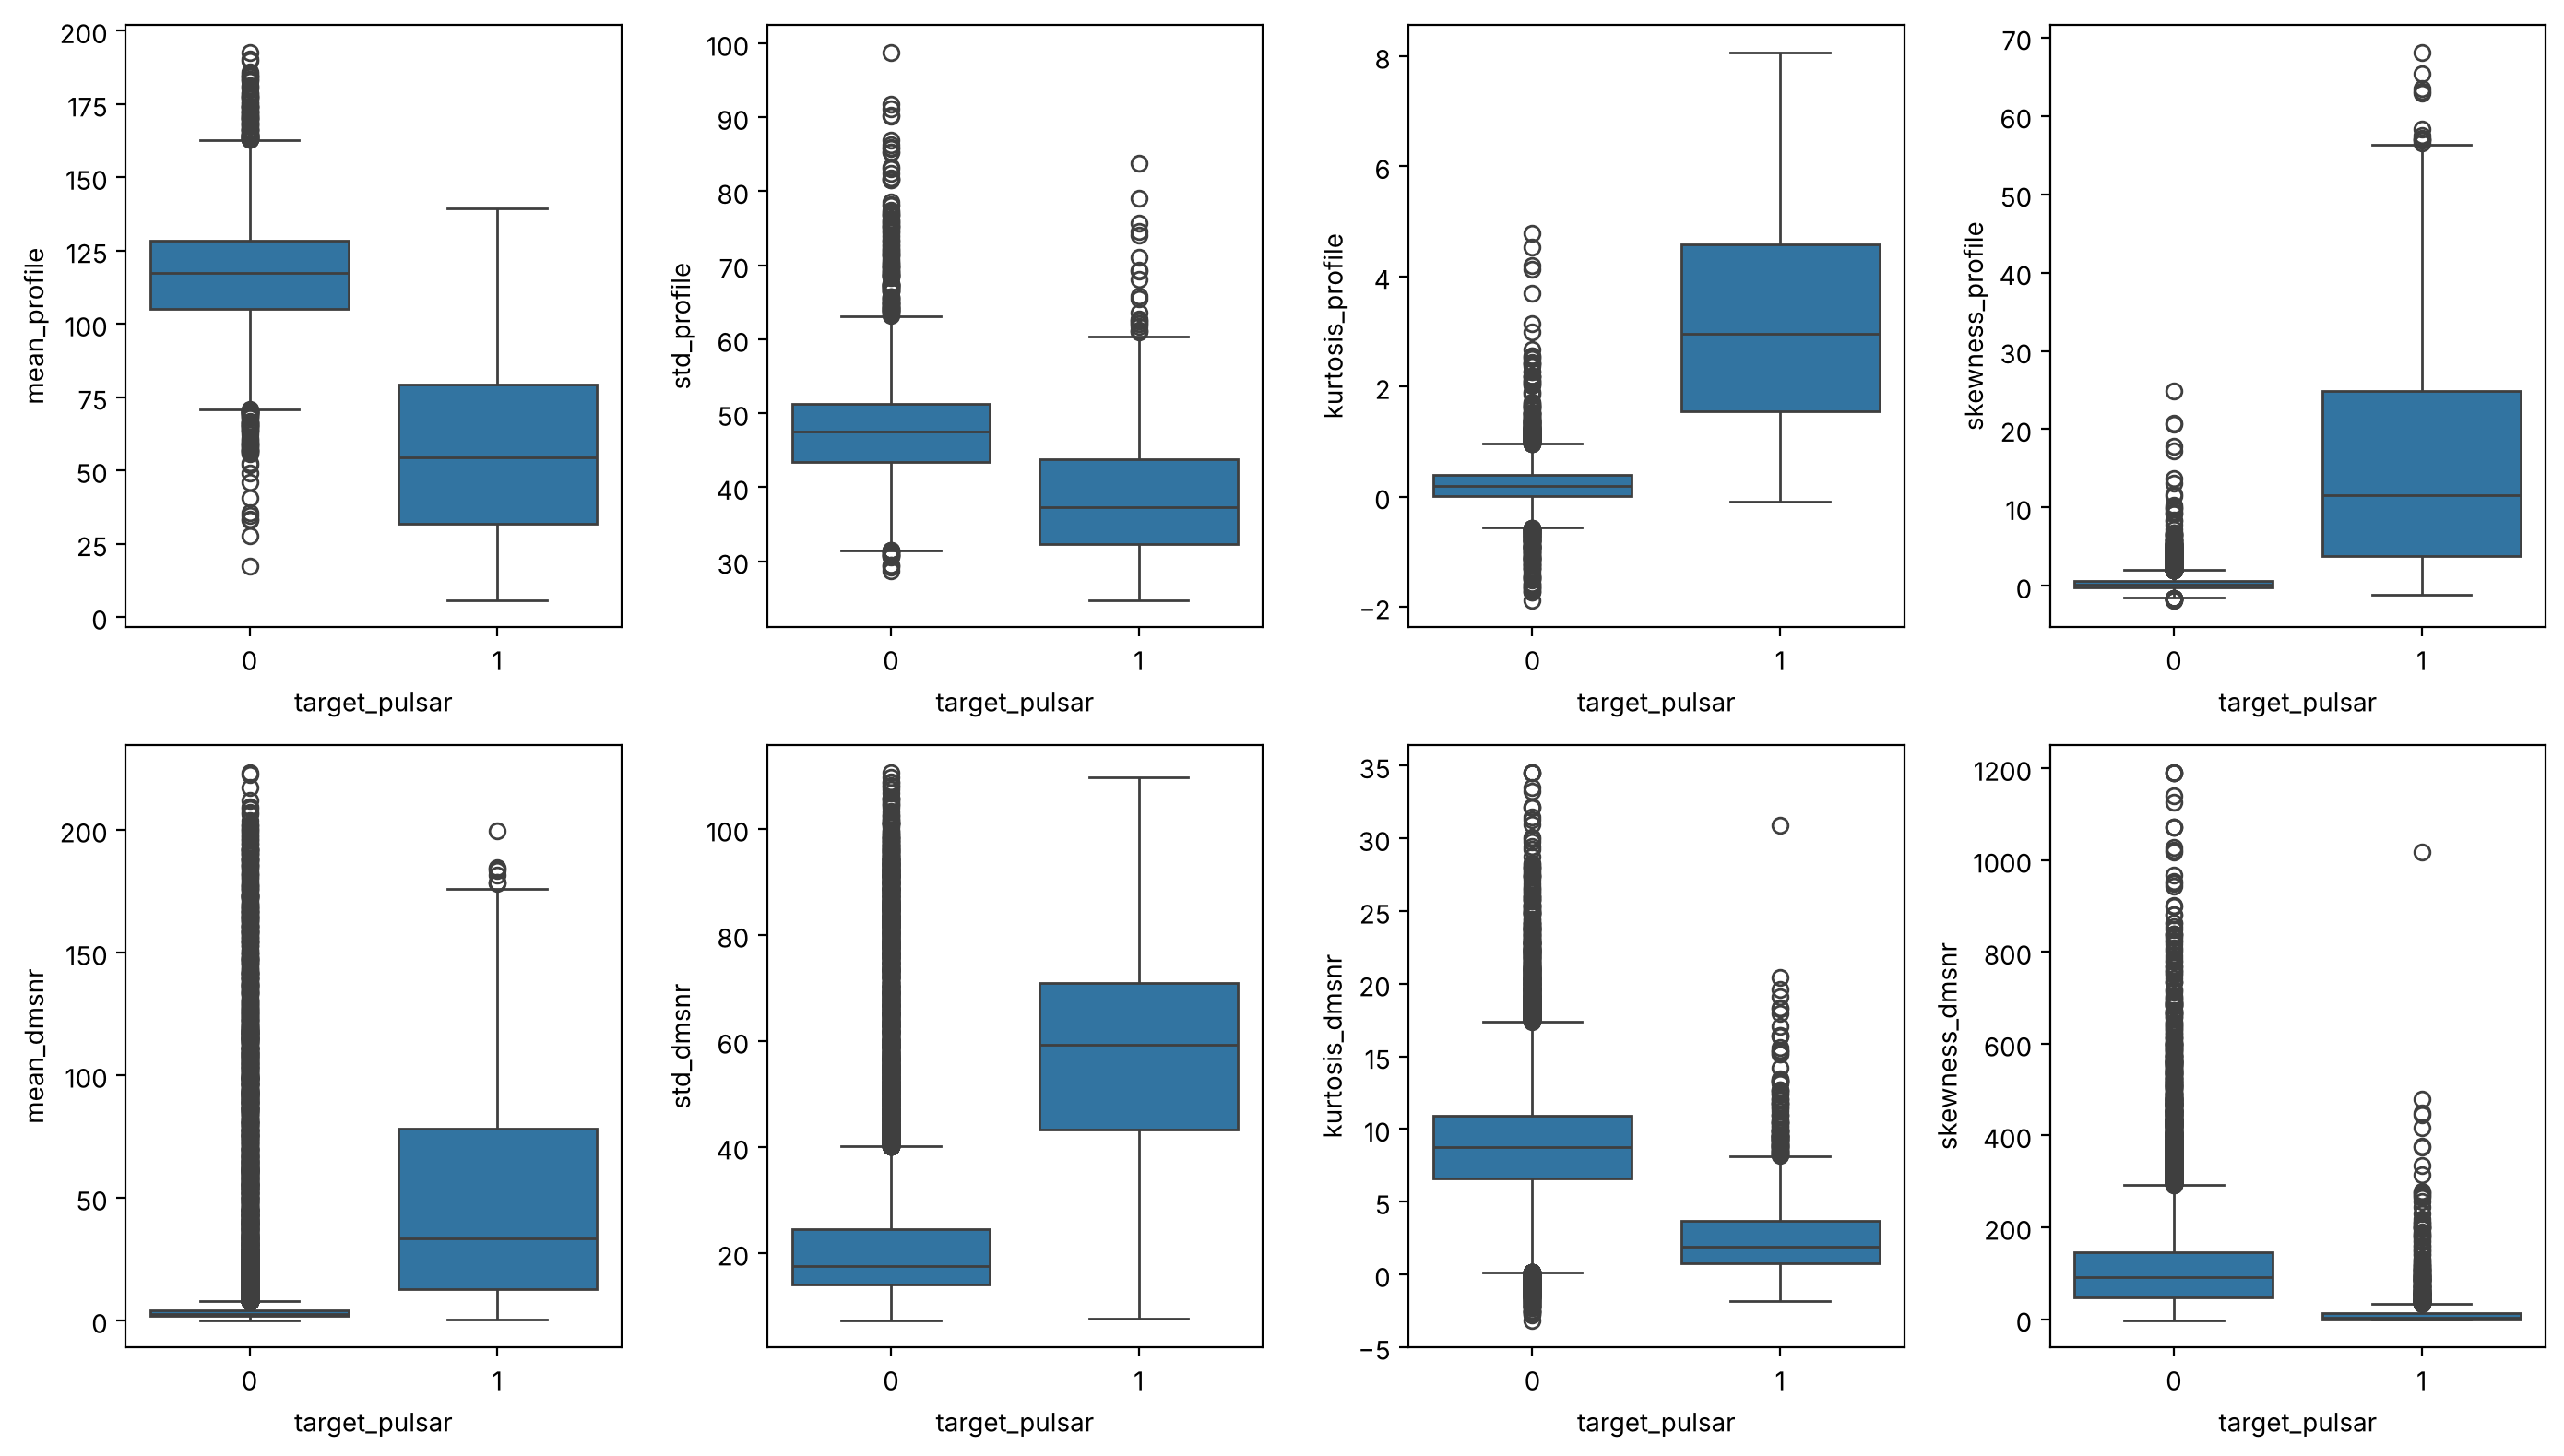

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(14, 8))
for ax, col in zip(axes.flat, features):
    sns.boxplot(data=df, x="target_pulsar", y=col, ax=ax)
plt.tight_layout()
plt.show()

In [ ]:
q1, q3 = df[features].quantile(0.25), df[features].quantile(0.75)
iqr = q3 - q1
is_outlier = ((df[features] < q1 - 1.5 * iqr) |
              (df[features] > q3 + 1.5 * iqr))
outlier_pulsars = is_outlier[df["target_pulsar"] == 1].sum()

pd.DataFrame({
    "odľahlé": is_outlier.sum(),
    "z toho pulzary [%]": (100 * outlier_pulsars / is_outlier.sum()).round(1),
})

,odľahlé,z toho pulzary [%]
mean_profile,1030,92.0
std_profile,262,52.3
kurtosis_profile,1596,85.0
skewness_profile,1901,69.0
mean_dmsnr,2927,43.8
std_dmsnr,2346,46.9
kurtosis_dmsnr,487,1.6
skewness_dmsnr,901,1.0


Odľahlých hodnôt je veľa (napr. 2 927 pri `mean_dmsnr`), no pri premenných integrovaného profilu **patrí 70 – 92 % z nich pulzarom**, hoci pulzary tvoria len 9 % dát. Odľahlé hodnoty teda nie sú chyby merania, ale práve **signál, ktorý hľadáme**. Keby sme ich odstránili, vyhodili by sme veľkú časť pulzarov. **Preto ich v dátach ponechávame.**

## 1.6 Korelácie

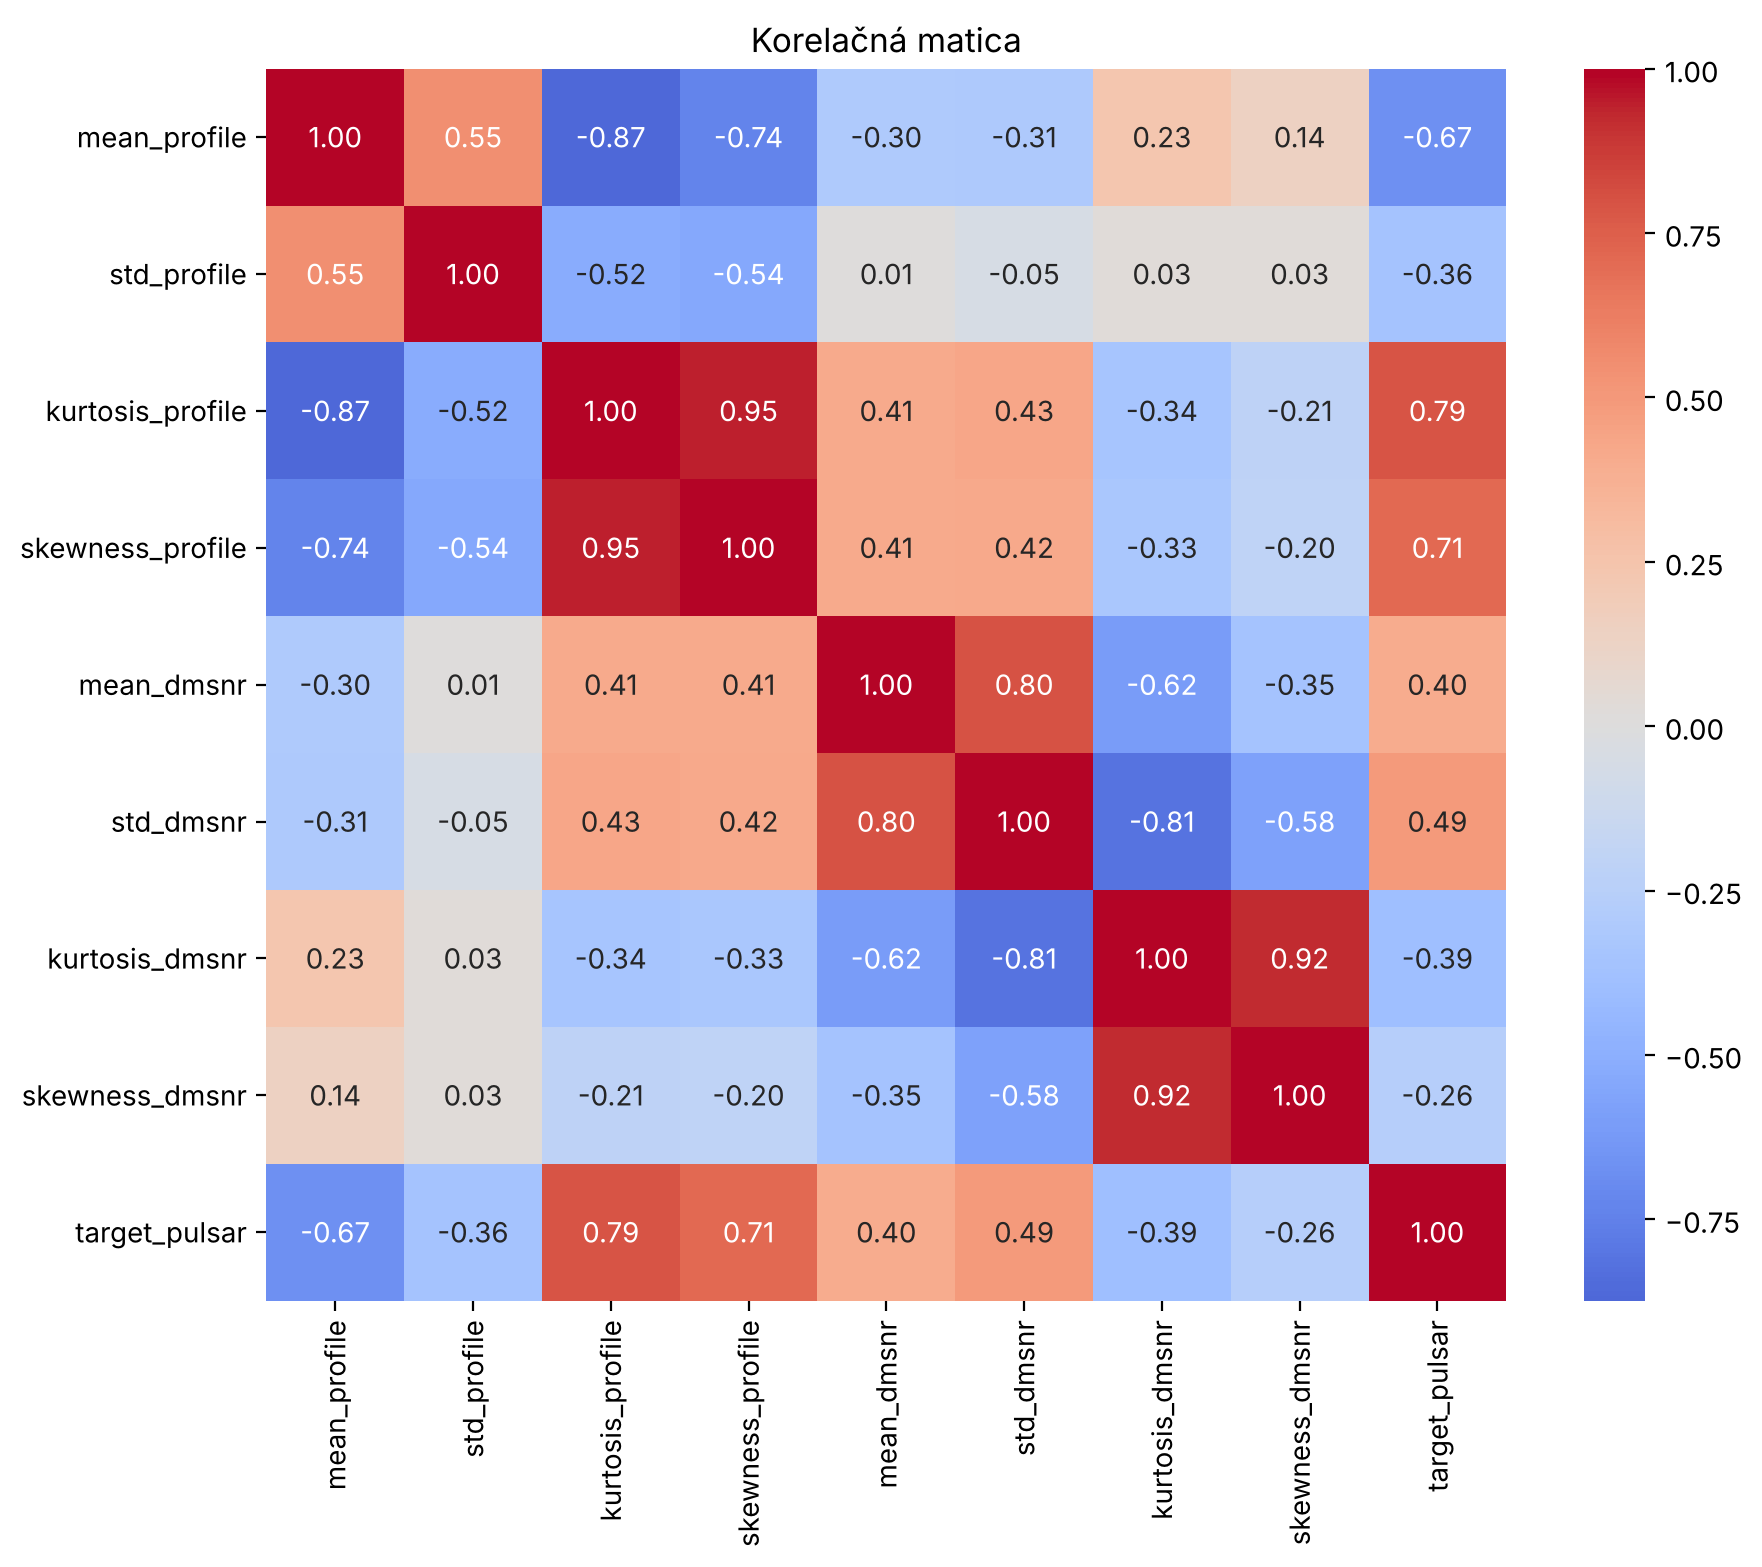

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelačná matica")
plt.show()

* Dve dvojice premenných sú **takmer zameniteľné**: `kurtosis_profile` a `skewness_profile` (r = 0,95), `kurtosis_dmsnr` a `skewness_dmsnr` (r = 0,92). Nesú takmer rovnakú informáciu, čo rieši výber premenných v časti 2.2.
* S cieľovou premennou najsilnejšie koreluje `kurtosis_profile` (r = 0,79) a `mean_profile` (r = −0,67), čo zodpovedá grafom vyššie.

# 2. Príprava dát a rozdelenie na trénovaciu a testovaciu časť
## 2.1 Rozdelenie dát
Dáta rozdelíme v pomere **80 : 20**. Parameter `stratify=y` zaručí, že v oboch častiach bude rovnaký podiel
pulzarov (pri nevyvážených triedach je to dôležité). Rozdelenie robíme **pred** výberom premenných a škálovaním,
aby sa žiadna informácia z testovacích dát nedostala do trénovania.

In [ ]:
X = df[features]
y = df["target_pulsar"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Trénovacie:", X_train.shape, "| Testovacie:", X_test.shape)
print("Podiel pulzarov v train:", round(y_train.mean(), 3))
print("Podiel pulzarov v test: ", round(y_test.mean(), 3))

Trénovacie: (14318, 8) | Testovacie: (3580, 8)
Podiel pulzarov v train: 0.092
Podiel pulzarov v test:  0.092


## 2.2 Výber premenných: odstránenie nadbytočných
Z korelačnej matice vidno dvojice premenných, ktoré nesú takmer rovnakú informáciu. Vyhľadáme všetky dvojice
s |r| > 0,9 a z každej ponecháme tú, ktorá **silnejšie koreluje s cieľovou premennou**.

In [ ]:
corr = X_train.corr()
target_corr = X_train.corrwith(y_train).abs()

for i, a in enumerate(features):
    for b in features[i + 1:]:
        if abs(corr.loc[a, b]) > 0.9:
            print(f"{a} vs {b}: r = {corr.loc[a, b]:.2f}")
            print(f"   korelácia s cieľom: {target_corr[a]:.2f}",
                  f"vs {target_corr[b]:.2f}")

kurtosis_profile vs skewness_profile: r = 0.95
   korelácia s cieľom: 0.79 vs 0.71
kurtosis_dmsnr vs skewness_dmsnr: r = 0.92
   korelácia s cieľom: 0.39 vs 0.26


Z každej dvojice vyhadzujeme **šikmosť (skewness)**, lebo slabšie koreluje s cieľovou premennou ako špicatosť (kurtosis). Overíme, že tým model nestratí výkon:

In [ ]:
to_drop = ["skewness_profile", "skewness_dmsnr"]
model = make_pipeline(StandardScaler(), LogisticRegression())

f1_all = cross_val_score(model, X_train, y_train, scoring="f1").mean()
f1_six = cross_val_score(model, X_train.drop(columns=to_drop), y_train,
                         scoring="f1").mean()
print("F1 s 8 premennými: ", round(f1_all, 3))
print("F1 so 6 premennými:", round(f1_six, 3))

F1 s 8 premennými:  0.873
F1 so 6 premennými: 0.869


F1 skóre (5-násobná krížová validácia na trénovacích dátach) sa zmenilo **len o 0,004**, čo je v rámci náhodného kolísania. Dve premenné boli teda **nadbytočné**: nepridávajú novú informáciu, iba zväčšujú model. Ďalej pracujeme so **6 premennými**.

In [ ]:
X_train = X_train.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)
list(X_train.columns)

['mean_profile',
 'std_profile',
 'kurtosis_profile',
 'mean_dmsnr',
 'std_dmsnr',
 'kurtosis_dmsnr']

## 2.3 Škálovanie a transformácie
* **Škálovanie** (`StandardScaler`, každá premenná bude mať priemer 0 a smerodajnú odchýlku 1) potrebujú
  modely, ktoré pracujú so vzdialenosťami alebo váhami: **logistická regresia, KNN a SVM**.
  Bez neho by `std_dmsnr` (hodnoty do ~110) prevalcovala `kurtosis_profile` (hodnoty ~0 až 8).
  **Random Forest** škálovanie nepotrebuje, rozhoduje podľa prahov jednotlivých premenných.
* Scaler vkladáme do **`Pipeline`** spolu s modelom. Vďaka tomu sa pri krížovej validácii naučí priemer
  a odchýlku vždy iba z trénovacích foldov, takže nedochádza k úniku informácie.
* **Kódovanie premenných** nie je potrebné, všetky premenné sú číselné.
* **Logaritmickú transformáciu** nerobíme: viaceré premenné nadobúdajú záporné hodnoty a odľahlé hodnoty
  sú pre nás užitočný signál (patria pulzarom), nie chyba, ktorú treba potlačiť.

# 3. Výber algoritmov a trénovanie
## Ako budeme modely hodnotiť
Pulzarov je iba ~9 %. Model, ktorý by vždy povedal „šum“, by mal presnosť (accuracy) **90,8 %**, a pritom
by nenašiel ani jeden pulzar. Accuracy je preto zavádzajúca. Sledujeme hlavne:

* **Recall (citlivosť)**: koľko zo skutočných pulzarov model našiel. Prehliadnutý pulzar je strata objavu.
* **Precision (presnosť pozitívnych)**: koľko z kandidátov označených ako pulzar je naozaj pulzar.
  Falošný poplach stojí astronóma čas na kontrolu.
* **F1 skóre**: harmonický priemer precision a recall. Podľa neho ladíme hyperparametre a vyberáme najlepší model.

## Optimalizácia hyperparametrov
Každý model ladíme pomocou **`GridSearchCV`**: vyskúša všetky kombinácie hyperparametrov z mriežky a každú
ohodnotí 5-násobnou krížovou validáciou na trénovacích dátach. Testovacie dáta ostávajú nedotknuté až do
finálneho porovnania.

In [ ]:
def tune(model, params):
    search = GridSearchCV(model, params, scoring="f1").fit(X_train, y_train)
    print("Najlepšie hyperparametre:", search.best_params_)
    print("F1 (krížová validácia):", round(search.best_score_, 3))
    return search.best_estimator_

Pri modeloch v `Pipeline` sa názov hyperparametra píše v tvare `krok__parameter`, napr. `svc__C` znamená
parameter `C` kroku `svc`.

Parameter `class_weight="balanced"` (pri LR, SVM a RF) zvýši váhu chýb na menšinovej triede, teda modelu viac
„záleží“ na pulzaroch. Necháme GridSearch rozhodnúť, či to pomôže.

## 3.1 Logistická regresia
**Ako funguje:** vypočíta vážený súčet premenných **z = w₀ + w₁x₁ + … + wₙxₙ** a pretransformuje ho
sigmoidou **p = 1 / (1 + e⁻ᶻ)** na pravdepodobnosť, že ide o pulzar. Ak p > 0,5, predikuje triedu 1.
Váhy hľadá maximalizáciou vierohodnosti.

**Prečo:** jednoduchý a interpretovateľný základný model. EDA ukázala, že triedy sú do veľkej miery
oddeliteľné aj jednou premennou, preto čakáme dobrý výsledok už od lineárneho modelu.

**Ladíme:** `C` je sila regularizácie (malé C = silnejšia regularizácia, jednoduchší model) a `class_weight`.

In [ ]:
log_reg = tune(
    make_pipeline(StandardScaler(), LogisticRegression()),
    {"logisticregression__C": [0.01, 0.1, 1, 10, 100],
     "logisticregression__class_weight": [None, "balanced"]},
)

Najlepšie hyperparametre: {'logisticregression__C': 10, 'logisticregression__class_weight': None}
F1 (krížová validácia): 0.872


## 3.2 K-najbližších susedov (KNN)
**Ako funguje:** model sa nič „neučí“, iba si zapamätá trénovacie dáta. Pre nový bod nájde *k* najbližších
bodov (euklidovská vzdialenosť) a priradí triedu, ktorá medzi nimi prevláda.

**Prečo:** nerobí žiadny predpoklad o tvare hranice medzi triedami, takže dokáže zachytiť aj nelineárne vzťahy.
Kvôli vzdialenostiam je nutné škálovanie.

**Ladíme:** `n_neighbors` (počet susedov, malé k = citlivé na šum, veľké k = príliš hladká hranica) a `weights`
(či majú bližší susedia väčší hlas).

In [ ]:
knn = tune(
    make_pipeline(StandardScaler(), KNeighborsClassifier()),
    {"kneighborsclassifier__n_neighbors": [3, 5, 9, 15, 25],
     "kneighborsclassifier__weights": ["uniform", "distance"]},
)

Najlepšie hyperparametre: {'kneighborsclassifier__n_neighbors': 9, 'kneighborsclassifier__weights': 'distance'}
F1 (krížová validácia): 0.875


## 3.3 Support Vector Machine (SVM)
**Ako funguje:** hľadá hranicu medzi triedami s **čo najväčším okrajom** (marginom) od najbližších bodov
(podporných vektorov). Pomocou **RBF jadra** dáta implicitne premietne do vyššej dimenzie, kde ich vie oddeliť
aj vtedy, ak v pôvodnom priestore oddeliteľné lineárne nie sú.

**Prečo:** výborne funguje na menšom počte číselných premenných a pri zložitejšej hranici medzi triedami.

**Ladíme:** `C` (koľko chýb model toleruje: veľké C = tvrdší okraj, riziko pretrénovania), `gamma` (dosah jedného
bodu: veľká gamma = kľukatejšia hranica) a `class_weight`.

In [ ]:
svm = tune(
    make_pipeline(StandardScaler(), SVC()),
    {"svc__C": [0.1, 1, 10],
     "svc__gamma": ["scale", 0.1, 1],
     "svc__class_weight": [None, "balanced"]},
)

Najlepšie hyperparametre: {'svc__C': 10, 'svc__class_weight': None, 'svc__gamma': 'scale'}
F1 (krížová validácia): 0.883


## 3.4 Random Forest
**Ako funguje:** natrénuje veľa rozhodovacích stromov. Každý strom sa učí na náhodnej vzorke riadkov
(bootstrap) a v každom uzle vyberá z náhodnej podmnožiny premenných. Výsledok je hlasovanie všetkých stromov.
Vďaka tomu je stabilnejší a menej náchylný na pretrénovanie ako jeden strom.

**Prečo:** nepotrebuje škálovanie, je odolný voči odľahlým hodnotám a vie zachytiť nelineárne vzťahy
aj interakcie premenných. Navyše ukáže, ktoré premenné sú pre rozhodovanie najdôležitejšie.

**Ladíme:** `max_depth` (maximálna hĺbka stromu), `min_samples_leaf` (minimálny počet pozorovaní v liste,
väčšie číslo = jednoduchšie stromy) a `class_weight`.

In [ ]:
forest = tune(
    RandomForestClassifier(random_state=42),
    {"max_depth": [None, 10],
     "min_samples_leaf": [1, 5],
     "class_weight": [None, "balanced"]},
)

Najlepšie hyperparametre: {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 1}
F1 (krížová validácia): 0.886


# 4. Vyhodnotenie a porovnanie modelov na testovacích dátach
Až teraz prvýkrát použijeme testovacie dáta, ktoré žiaden model ani GridSearch predtým nevideli.

In [ ]:
models = {"Logistická regresia": log_reg, "KNN": knn,
          "SVM": svm, "Random Forest": forest}

rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})

results = pd.DataFrame(rows).set_index("Model").round(3)
print("Accuracy modelu, ktorý vždy tipne šum:", round(1 - y_test.mean(), 3))
results.sort_values("F1", ascending=False)

Accuracy modelu, ktorý vždy tipne šum: 0.908


,Accuracy,Precision,Recall,F1
Model,,,,
KNN,0.982,0.940,0.854,0.895
SVM,0.981,0.933,0.851,0.890
Random Forest,0.980,0.919,0.863,0.890
Logistická regresia,0.980,0.954,0.820,0.882


* Všetky štyri modely dosahujú **accuracy 98 %**, oproti 90,8 % pri „hlúpom“ modeli, ktorý vždy tvrdí šum. Accuracy však modely takmer nerozlíši, preto sa pozeráme na ďalšie metriky.
* **F1 skóre sa pohybuje od 0,882 do 0,895**. Rozdiely medzi modelmi sú malé (v testovacej vzorke je len 328 pulzarov, takže rozdiel 0,01 predstavuje iba niekoľko kandidátov).
* **Logistická regresia** má najvyššiu precision (0,954, najmenej falošných poplachov), ale najnižší recall (0,820, prehliadne najviac pulzarov).
* **Random Forest** má najvyšší recall (0,863), teda nájde najviac pulzarov, za cenu o niečo viac falošných poplachov.
* **KNN** má najlepší kompromis (F1 = 0,895).

## 4.1 Matice zámen
Riadky = skutočnosť, stĺpce = predikcia. Vpravo hore sú **falošné poplachy** (šum označený ako pulzar),
vľavo dole **prehliadnuté pulzary**.

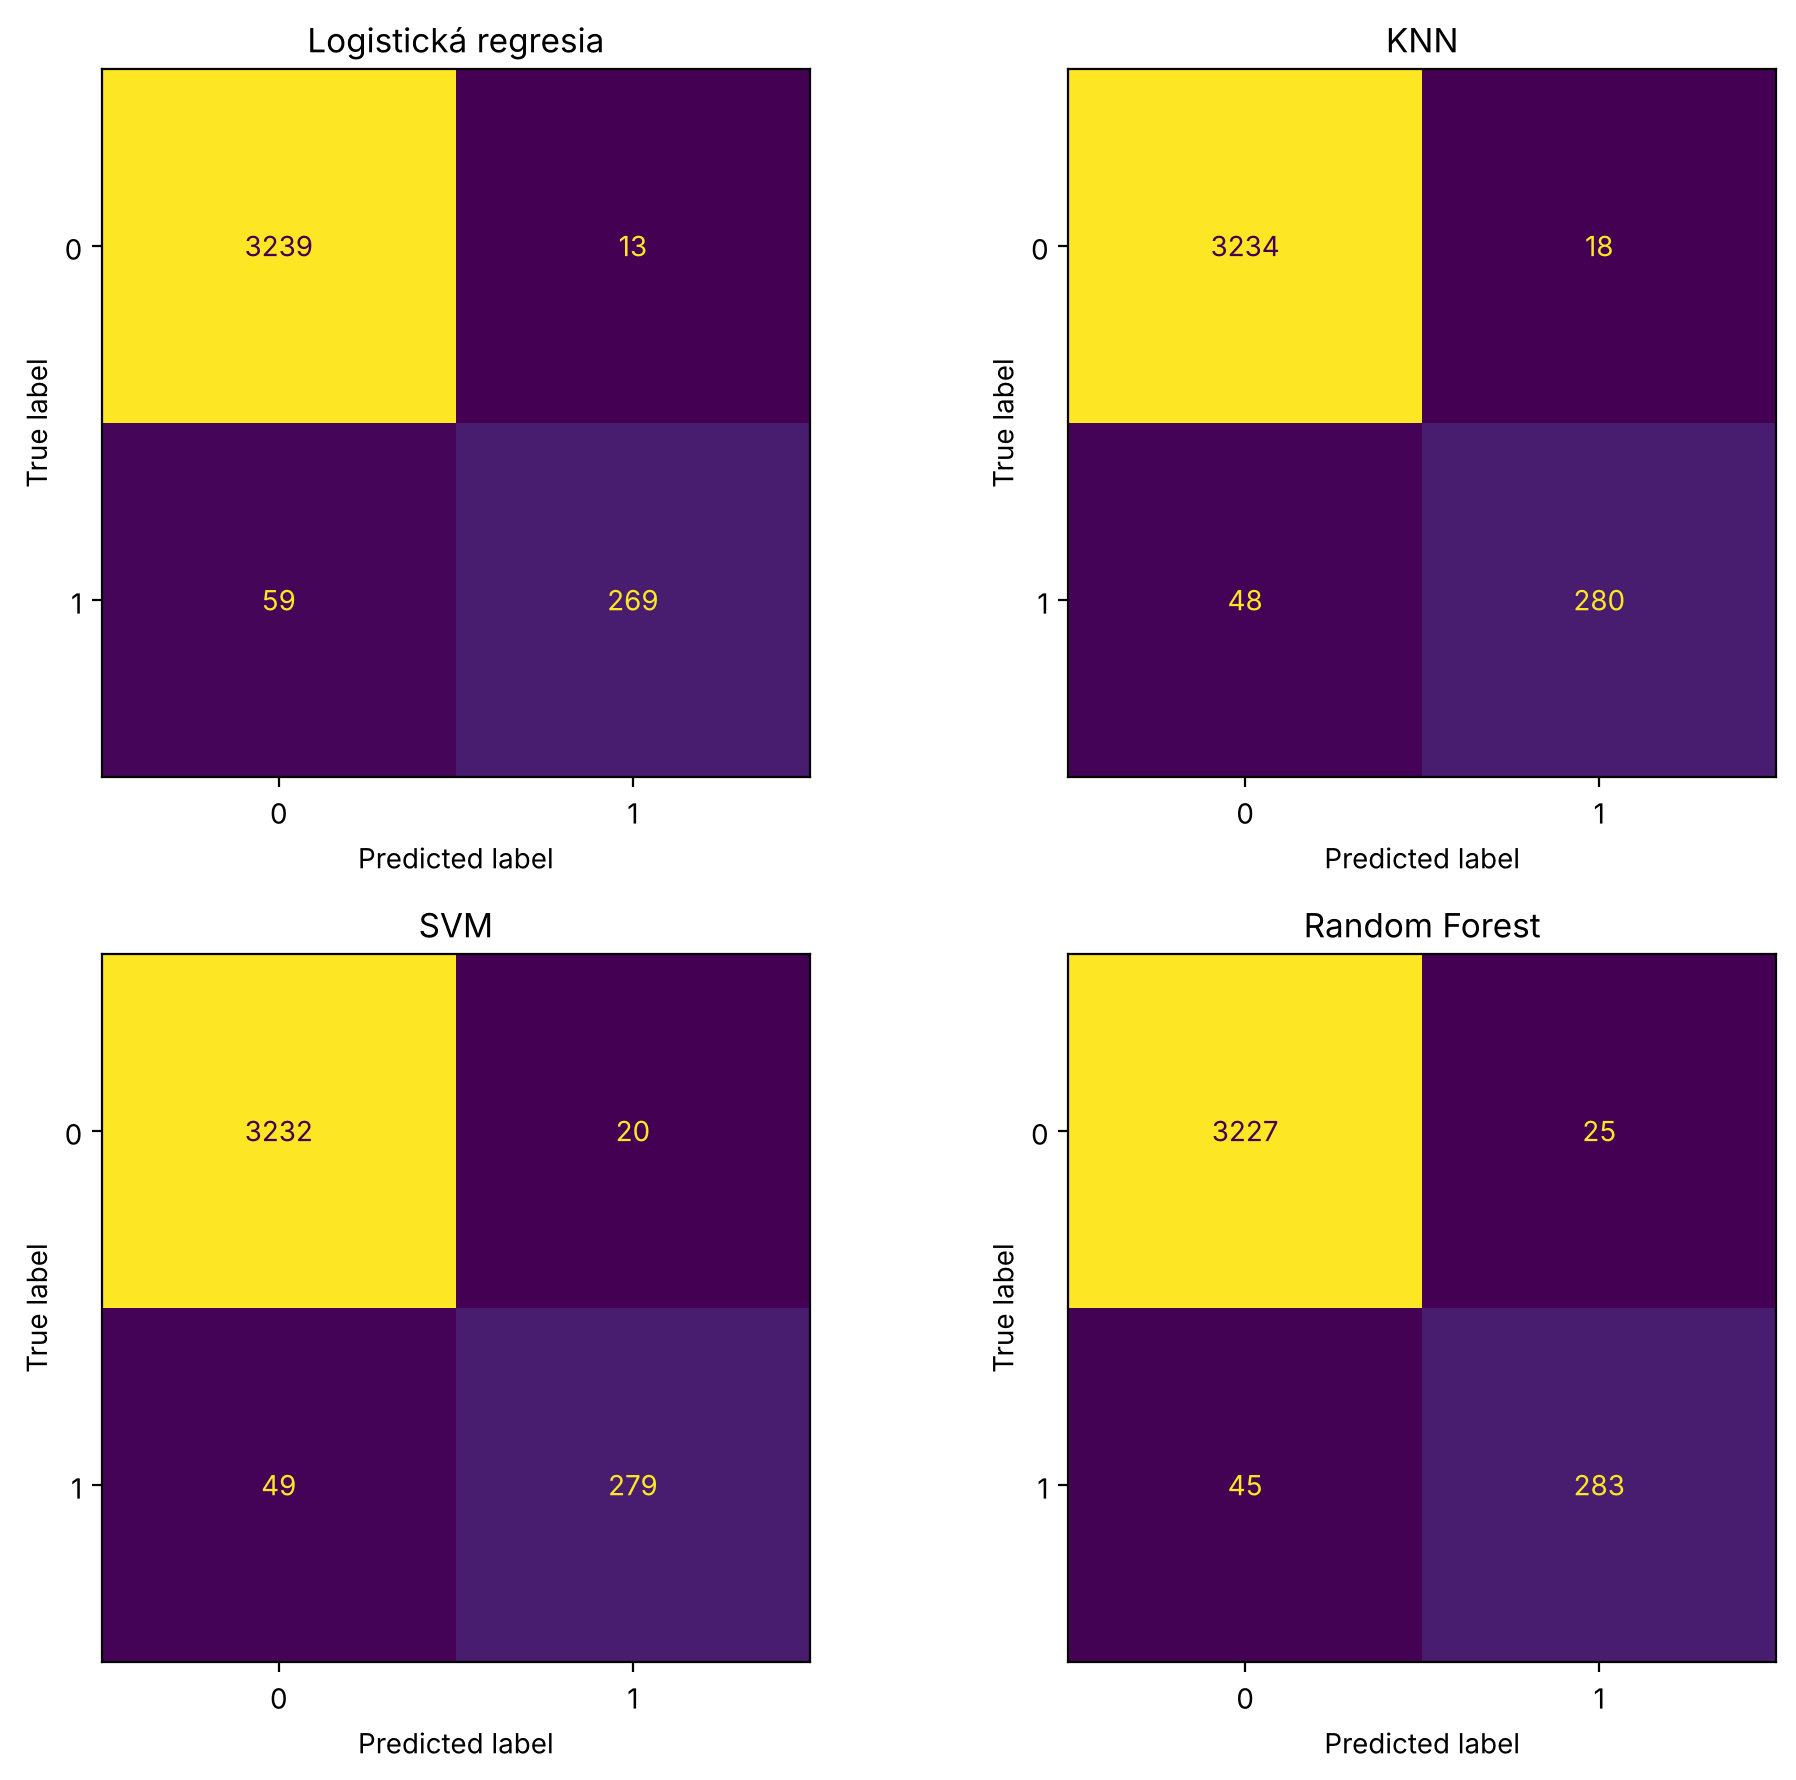

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (name, model) in zip(axes.flat, models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test,
                                          ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

Napríklad Random Forest z 328 pulzarov v testovacích dátach správne našiel **283** a prehliadol 45. Spomedzi 3 252 kandidátov so šumom označil ako pulzar iba 25. Logistická regresia vyvolala len 13 falošných poplachov, no prehliadla 59 pulzarov.

## 4.2 ROC krivky
ROC krivka ukazuje, ako sa mení podiel nájdených pulzarov (true positive rate) a falošných poplachov
(false positive rate) pri rôznych rozhodovacích prahoch. **AUC** (plocha pod krivkou) = pravdepodobnosť,
že model priradí náhodnému pulzaru vyššie skóre ako náhodnému šumu. 1 = dokonalý model, 0,5 = hádanie.

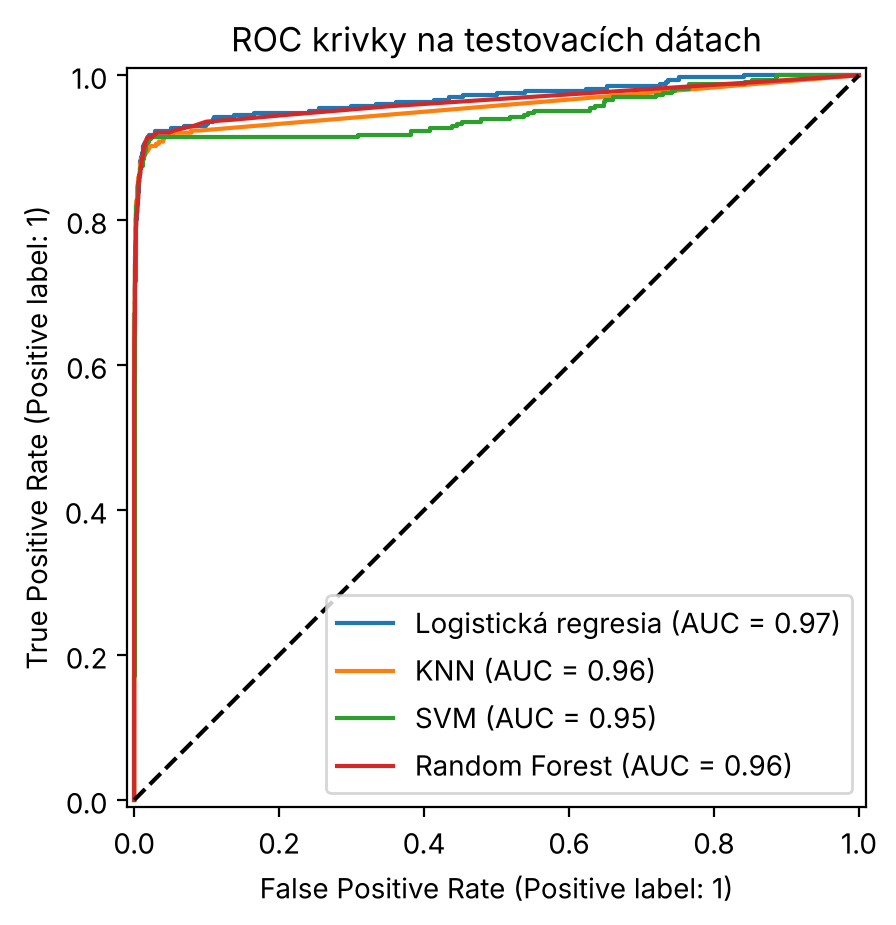

In [ ]:
ax = plt.gca()
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test,
                                   name=name, ax=ax)
plt.plot([0, 1], [0, 1], "k--")
plt.title("ROC krivky na testovacích dátach")
plt.show()

Všetky modely majú **AUC 0,95 – 0,97**, teda veľmi dobrú schopnosť odlíšiť pulzar od šumu. Krivky sú pri ľavom hornom rohu takmer totožné. Pri nízkej miere falošných poplachov (to je oblasť, ktorá nás reálne zaujíma) sa modely správajú prakticky rovnako. Najvyššiu AUC má logistická regresia (0,97): lineárna hranica tu stačí.

## 4.3 Najlepší model

In [ ]:
best_name = results["F1"].idxmax()
print("Najlepší model podľa F1:", best_name, "\n")
best_pred = models[best_name].predict(X_test)
print(classification_report(y_test, best_pred,
                            target_names=["šum", "pulzar"]))

Najlepší model podľa F1: KNN 

              precision    recall  f1-score   support

         šum       0.99      0.99      0.99      3252
      pulzar       0.94      0.85      0.89       328

    accuracy                           0.98      3580
   macro avg       0.96      0.92      0.94      3580
weighted avg       0.98      0.98      0.98      3580



Najvyššie F1 na testovacích dátach dosiahol **KNN (k = 9, bližší susedia majú väčšiu váhu)**: nájde 85 % pulzarov a z kandidátov, ktoré označí ako pulzar, je 94 % skutočných.

**Kedy by sme volili iný model:**
* ak je priorita **nenechať ujsť žiadny pulzar** → **Random Forest** (najvyšší recall),
* ak chceme **jednoduchý, rýchly a vysvetliteľný** model → **logistická regresia**, ktorá je len o 0,013 F1 horšia a dá sa zapísať jedným vzorcom.

## 4.4 Ktoré premenné rozhodujú?
Random Forest meria dôležitosť premennej podľa toho, o koľko v priemere zníži nečistotu (Gini) v uzloch,
kde sa podľa nej delí.

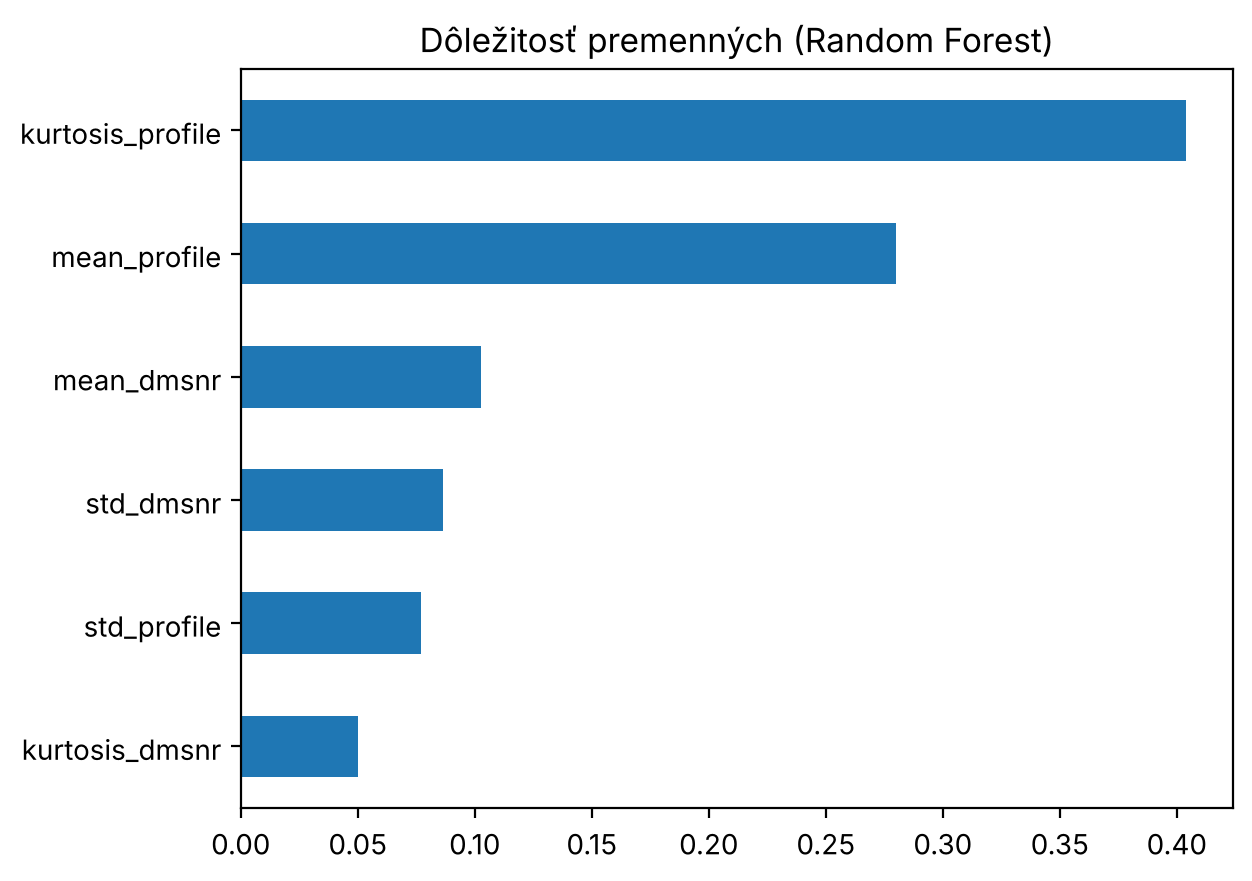

In [ ]:
importance = pd.Series(forest.feature_importances_, index=X_train.columns)
importance = importance.sort_values()
importance.plot.barh(title="Dôležitosť premenných (Random Forest)")
plt.show()

Najdôležitejšia je **špicatosť integrovaného profilu** (`kurtosis_profile`, 40 %) a **priemer integrovaného profilu** (28 %). Spolu tvoria takmer 70 % rozhodovania. Má to aj fyzikálny zmysel: skutočný pulzar vytvára **krátky, ostrý pulz**, ktorý sa opakuje pri každej otáčke, kým šum je rozmazaný a plochý.

# 5. Záver

* Na datasete HTRU2 (17 898 kandidátov, 9 % pulzarov) sme natrénovali a porovnali **4 klasifikačné modely**: logistickú regresiu, KNN, SVM a Random Forest. Hyperparametre sme ladili cez `GridSearchCV` s 5-násobnou krížovou validáciou podľa F1 skóre.
* **Príprava dát:** dáta sú čisté (bez chýbajúcich hodnôt a duplicít). Odľahlé hodnoty sme ponechali, lebo prevažne patria pulzarom. Dve premenné (`skewness_profile`, `skewness_dmsnr`) sme vyradili ako nadbytočné, lebo korelovali s inými premennými na úrovni r > 0,9 a ich odstránenie výkon nezhoršilo.
* **Výsledky:** všetky modely dosiahli accuracy ~98 %, F1 0,88 – 0,90 a AUC 0,95 – 0,97. Najlepšie F1 má **KNN (0,895)**, najvyšší recall **Random Forest (0,863)**.
* **Hlavné zistenia:**
  1. Pri nevyvážených triedach je accuracy zavádzajúca. Model, ktorý nenájde ani jeden pulzar, má 90,8 %.
  2. Rozdiely medzi modelmi sú malé, pretože triedy sa dajú dobre oddeliť už podľa tvaru integrovaného profilu. Aj jednoduchá logistická regresia je takmer rovnako dobrá ako zložitejšie modely.
  3. Rozhodujúca je špicatosť a priemer integrovaného profilu: pulzar má ostrý, pravidelný pulz.
* **Možné rozšírenia:** posunúť rozhodovací prah (napr. z 0,5 na 0,3) a tým zvýšiť recall, alebo vyskúšať gradient boosting (XGBoost).